# 인천 음식점·카페 폐업위기 조기경보: LightGBM 예측, SHAP 해석, 성능평가
- 데이터: `[전처리10_최종]인천_사업체-분기_패널_군구인구_YoY보완 (2).zip` (사업체×분기 패널, 531,398행)
- 타깃: `다음분기_폐업여부` (기준분기 말 영업 중인 사업체가 다음 분기에 폐업하면 1)
- 예측인자: 지정한 26개 변수
- 순서: ① 데이터 준비 → ② 시간순 분할 → ③ LightGBM 학습·확률 보정 → ④ 성능평가 → ⑤ SHAP 변수 중요도

셀을 위에서부터 차례로 실행하면 됩니다. 결과 표는 `results/`, 그림은 `figures/`에 저장됩니다.

## 0. 환경 준비
Colab이라면 아래 셀을 먼저 실행하세요(라이브러리와 한글 글꼴 설치).

In [1]:
!pip -q install lightgbm shap koreanize-matplotlib

In [2]:
DATA_PATH = "[전처리10_최종]인천_사업체-분기_패널_군구인구_YoY보완 (2).zip"  # 업로드한 zip 파일 이름과 똑같이 적기
RESULT_DIR, FIG_DIR = "results", "figures"
SEED = 42
N_BOOT = 1000   # 부트스트랩 반복 횟수(오래 걸리면 200으로)

import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 그래프 한글 표시
import lightgbm as lgb, shap, sklearn
from scipy import stats
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss, log_loss,
                             precision_recall_curve, fbeta_score, confusion_matrix)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
os.makedirs(RESULT_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)
print("lightgbm", lgb.__version__, "| shap", shap.__version__, "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


lightgbm 4.7.0 | shap 0.52.0 | scikit-learn 1.9.1 | pandas 3.0.5


## 1. 데이터 준비

In [3]:
df = pd.read_csv(DATA_PATH, low_memory=False)   # zip 안의 CSV를 바로 읽음
Y = "다음분기_폐업여부"
print(df.shape)
print("폐업(1) %d건 / 전체 %d건 = %.2f%% (폐업:비폐업 = 1:%.0f)"
      % (df[Y].sum(), len(df), df[Y].mean() * 100, (1 - df[Y].mean()) / df[Y].mean()))

(531398, 79)
폐업(1) 14141건 / 전체 531398건 = 2.66% (폐업:비폐업 = 1:37)


In [4]:
# 예측인자 26개
FEATURES = [
    "업태구분_2진수",                                   # 0=음식점, 1=카페
    "업력개월", "시설규모_log", "다중이용업소여부",
    "분기번호", "시간순번",
    "군구_총인구", "군구_인구증감률_QoQ", "군구_인구증감률_YoY",
    "군구_인구천명당_전체점포수", "군구_인구천명당_동일업태점포수",
    "군구업태_개업률", "군구업태_폐업률", "군구업태_폐업률_lag1", "군구업태_폐업률_lag4",
    "군구업태_폐업률_4Q평균", "군구업태_공급수요격차",
    "읍면동_영업점포수", "읍면동_개업률", "읍면동_폐업률", "읍면동_점포수증감률",
    "읍면동_폐업률_lag1", "읍면동_폐업률_lag4", "읍면동_폐업률_4Q평균",
    "읍면동업태_영업점포수", "읍면동업태_점포비중",
]
# 모델에는 넣지 않지만 분할·집계·부트스트랩에 쓰는 관리용 열
KEEP = ["관리번호", "기준분기", "군구명_개편후", "업태구분명"]

missing = [c for c in FEATURES + KEEP + [Y] if c not in df.columns]
assert not missing, f"없는 열: {missing}"
df = df[KEEP + FEATURES + [Y]].copy()

# 다중이용업소여부: Y/N 문자 → 1/0
df["다중이용업소여부"] = df["다중이용업소여부"].map({"Y": 1, "N": 0}).astype(float)

print(len(FEATURES), "개 예측인자")
print("결측 비율(%):", (df[FEATURES].isna().mean() * 100).round(2)[lambda s: s > 0].to_dict(),
      "→ LightGBM이 결측을 직접 처리하므로 따로 채우지 않음")
print("업태 확인:\n", pd.crosstab(df["업태구분_2진수"], df["업태구분명"]))

26 개 예측인자
결측 비율(%): {'시설규모_log': 1.36} → LightGBM이 결측을 직접 처리하므로 따로 채우지 않음
업태 확인:
 업태구분명        음식점     카페
업태구분_2진수               
0         464197      0
1              0  67201


In [5]:
# 서로 매우 비슷한 변수 쌍(|상관| > 0.8): SHAP 해석 시 묶어서 봐야 함
corr = df[FEATURES].corr().abs()
pairs = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(FEATURES) for b in FEATURES[i + 1:] if corr.loc[a, b] > 0.8]
pd.DataFrame(pairs, columns=["변수1", "변수2", "|상관계수|"]).sort_values("|상관계수|", ascending=False)

,변수1,변수2,|상관계수|
0,업태구분_2진수,읍면동업태_점포비중,0.991
1,읍면동_영업점포수,읍면동업태_영업점포수,0.879


## 2. 시간순 분할
무작위로 나누지 않고 기준분기 순서대로 나눕니다(같은 사업체가 여러 분기에 반복 관측되므로).
- 학습: 2023Q1~2024Q4 (시간순번 1~8)
- 검증: 2025Q1~2025Q4 (9~12) → 조기 종료, 확률 보정, 경보 임계값
- 테스트: 2026Q1~2026Q2 (13~14) → 최종 성능평가 1회

In [6]:
T = "시간순번"
tr, va, te = df[df[T] <= 8], df[df[T].between(9, 12)], df[df[T] >= 13]
split = pd.DataFrame({n: {"기준분기": f"{d['기준분기'].min()}~{d['기준분기'].max()}", "관측치": len(d),
                          "폐업": int(d[Y].sum()), "폐업비율(%)": round(d[Y].mean() * 100, 2),
                          "사업체수": d["관리번호"].nunique()}
                      for n, d in [("학습", tr), ("검증", va), ("테스트", te)]}).T
split.to_csv(f"{RESULT_DIR}/01_데이터분할.csv", encoding="utf-8-sig")
split

,기준분기,관측치,폐업,폐업비율(%),사업체수
학습,2023Q1~2024Q4,307042,8371,2.73,45365
검증,2025Q1~2025Q4,150316,4076,2.71,40325
테스트,2026Q1~2026Q2,74040,1694,2.29,37887


## 3. LightGBM 학습과 확률 보정
- 클래스 불균형(약 1:37)은 데이터를 늘리거나 줄이지 않음. 이전 비교에서 가중치 미적용이 검증 PR-AUC가 더 높았음.
- 검증 데이터의 PR-AUC가 100라운드 동안 오르지 않으면 학습을 멈춤(조기 종료).
- 군구별로 확률을 더해 예상 폐업 수를 구하므로, 검증 데이터로 확률을 실제 폐업률에 맞게 보정(Isotonic)함.

In [7]:
PARAMS = dict(objective="binary", metric="average_precision", learning_rate=0.03, num_leaves=63,
              min_child_samples=200, feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1,
              lambda_l2=5.0, seed=SEED, verbose=-1)
dtr = lgb.Dataset(tr[FEATURES], tr[Y])
dva = lgb.Dataset(va[FEATURES], va[Y], reference=dtr)
model = lgb.train(PARAMS, dtr, num_boost_round=3000, valid_sets=[dva],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
print("트리 수:", model.best_iteration, "| 검증 PR-AUC:", round(model.best_score["valid_0"]["average_precision"], 4))
model.save_model(f"{RESULT_DIR}/lgbm_model.txt")

p_va_raw = model.predict(va[FEATURES])
iso = IsotonicRegression(out_of_bounds="clip", y_min=1e-6, y_max=1 - 1e-6).fit(p_va_raw, va[Y])

# 경보 임계값: 폐업을 놓치지 않는 쪽에 무게를 둔 F2 점수가 최대인 값(검증 데이터에서 결정)
p_va = iso.predict(p_va_raw)
pr, rc, th = precision_recall_curve(va[Y], p_va)
f2 = 5 * pr * rc / np.maximum(4 * pr + rc, 1e-12)
THR = th[np.argmax(f2[:-1])]
print("경보 임계값(F2 기준): %.4f" % THR)

트리 수: 209 | 검증 PR-AUC: 0.057


경보 임계값(F2 기준): 0.0342


## 4. 성능평가(테스트 2026Q1~Q2)
- 주 지표 PR-AUC: 폐업 사업체를 얼마나 위쪽 순위에 올리는지. 무작위로 찍으면 폐업 비율과 같음.
- ROC-AUC, 상위 k% 재현율·정밀도·Lift, Brier score, Log loss

In [8]:
def topk(y, p, k):
    n = max(1, int(len(p) * k)); idx = np.argsort(-p)[:n]
    rec = y[idx].sum() / y.sum(); prec = y[idx].mean()
    return rec, prec, prec / y.mean()

def evaluate(y, p, name):
    y = np.asarray(y); p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6)
    r = {"구분": name, "관측치": len(y), "폐업": int(y.sum()), "폐업비율": y.mean(),
         "PR-AUC": average_precision_score(y, p), "PR-AUC/무작위": average_precision_score(y, p) / y.mean(),
         "ROC-AUC": roc_auc_score(y, p)}
    for k in (0.05, 0.10):
        rec, prec, lift = topk(y, p, k)
        r[f"Recall@{int(k*100)}%"], r[f"Precision@{int(k*100)}%"], r[f"Lift@{int(k*100)}%"] = rec, prec, lift
    r["Brier"], r["LogLoss"] = brier_score_loss(y, p), log_loss(y, p)
    return r

yte = te[Y].values
p_te_raw = model.predict(te[FEATURES])
p_te = iso.predict(p_te_raw)
perf = pd.DataFrame([evaluate(va[Y], p_va, "검증(2025)"),
                     evaluate(yte, p_te_raw, "테스트(보정 전)"),
                     evaluate(yte, p_te, "테스트(보정 후)")]).set_index("구분")
perf.round(4).to_csv(f"{RESULT_DIR}/02_전체성능.csv", encoding="utf-8-sig")
perf.round(4)

,관측치,폐업,폐업비율,PR-AUC,PR-AUC/무작위,ROC-AUC,Recall@5%,Precision@5%,Lift@5%,Recall@10%,Precision@10%,Lift@10%,Brier,LogLoss
구분,,,,,,,,,,,,,,
검증(2025),150316,4076,0.0271,0.0558,2.0570,0.6529,0.1290,0.0700,2.5812,0.2233,0.0605,2.2327,0.0260,0.1201
테스트(보정 전),74040,1694,0.0229,0.0529,2.3123,0.6339,0.1246,0.0570,2.4911,0.2184,0.0500,2.1842,0.0221,0.1065
테스트(보정 후),74040,1694,0.0229,0.0508,2.2223,0.6336,0.1234,0.0565,2.4675,0.2184,0.0500,2.1842,0.0221,0.1062


In [9]:
# 임계값을 적용했을 때의 경보 결과(혼동행렬)
flag = (p_te >= THR).astype(int)
tn, fp, fn, tp = confusion_matrix(yte, flag).ravel()
print(f"경보 {flag.sum():,}건 중 실제 폐업 {tp:,}건 → 정밀도 {tp/(tp+fp):.3f}")
print(f"실제 폐업 {yte.sum():,}건 중 경보로 잡은 것 {tp:,}건 → 재현율 {tp/(tp+fn):.3f} | F2 {fbeta_score(yte, flag, beta=2):.3f}")
pd.DataFrame([[tn, fp], [fn, tp]], index=["실제 0(영업)", "실제 1(폐업)"], columns=["예측 0", "예측 1(경보)"])

경보 18,215건 중 실제 폐업 698건 → 정밀도 0.038
실제 폐업 1,694건 중 경보로 잡은 것 698건 → 재현율 0.412 | F2 0.140


,예측 0,예측 1(경보)
실제 0(영업),54829,17517
실제 1(폐업),996,698


In [10]:
# 사업체 단위 부트스트랩 95% 신뢰구간(같은 사업체가 여러 분기에 있으므로 사업체를 단위로 다시 뽑음)
uid, inv = np.unique(te["관리번호"].values, return_inverse=True)
rows_of = np.split(np.argsort(inv, kind="stable"), np.cumsum(np.bincount(inv))[:-1])
rng = np.random.default_rng(SEED)
boot = {"PR-AUC": [], "ROC-AUC": [], "Recall@10%": [], "Brier": []}
for _ in range(N_BOOT):
    idx = np.concatenate([rows_of[i] for i in rng.integers(0, len(uid), len(uid))])
    yb, pb = yte[idx], p_te[idx]
    boot["PR-AUC"].append(average_precision_score(yb, pb)); boot["ROC-AUC"].append(roc_auc_score(yb, pb))
    boot["Recall@10%"].append(topk(yb, pb, 0.10)[0]); boot["Brier"].append(brier_score_loss(yb, pb))
ci = pd.DataFrame({k: {"추정값": np.mean(v), "95%CI 하한": np.percentile(v, 2.5), "95%CI 상한": np.percentile(v, 97.5)}
                   for k, v in boot.items()}).T
ci.round(4).to_csv(f"{RESULT_DIR}/03_부트스트랩_95CI.csv", encoding="utf-8-sig")
ci.round(4)

,추정값,95%CI 하한,95%CI 상한
PR-AUC,0.0509,0.0444,0.0577
ROC-AUC,0.6336,0.6202,0.6466
Recall@10%,0.2153,0.1968,0.2352
Brier,0.0221,0.0210,0.0231


In [11]:
# 업태별·군구별 성능
sub = [evaluate(yte[i], p_te[i], f"업태={g}") for g, i in te.groupby("업태구분명").indices.items()]
sub += [evaluate(yte[i], p_te[i], f"군구={g}") for g, i in te.groupby("군구명_개편후").indices.items()]
sub = pd.DataFrame(sub).set_index("구분")[["관측치", "폐업", "폐업비율", "PR-AUC", "PR-AUC/무작위", "ROC-AUC", "Recall@10%"]]
sub.round(4).to_csv(f"{RESULT_DIR}/04_업태_군구별_성능.csv", encoding="utf-8-sig")
sub.round(4)

,관측치,폐업,폐업비율,PR-AUC,PR-AUC/무작위,ROC-AUC,Recall@10%
구분,,,,,,,
업태=음식점,64831,1493,0.0230,0.0551,2.3936,0.6446,0.2237
업태=카페,9209,201,0.0218,0.0269,1.2344,0.5637,0.1443
군구=강화군,3609,43,0.0119,0.0175,1.4727,0.6350,0.1628
군구=검단구,4066,111,0.0273,0.0370,1.3548,0.5974,0.1351
군구=계양구,5771,113,0.0196,0.0303,1.5487,0.6334,0.1858
군구=남동구,11649,236,0.0203,0.0315,1.5536,0.6156,0.1864
군구=미추홀구,10007,234,0.0234,0.0863,3.6901,0.6464,0.2436
군구=부평구,10413,233,0.0224,0.0355,1.5848,0.6278,0.1803
군구=서해구,9345,259,0.0277,0.0455,1.6432,0.6469,0.2008


### 예상 폐업률 vs 실제 폐업률(군구·업태별 집계)
사업체별 보정 확률을 더하면 예상 폐업 수, 영업 점포 수로 나누면 예상 폐업률이 됩니다.

In [12]:
agg = te.assign(예측=p_te).groupby(["기준분기", "군구명_개편후", "업태구분명"]).agg(
    영업점포수=(Y, "size"), 실제폐업=(Y, "sum"), 예상폐업=("예측", "sum")).reset_index()
agg["실제폐업률(%)"] = agg["실제폐업"] / agg["영업점포수"] * 100
agg["예상폐업률(%)"] = agg["예상폐업"] / agg["영업점포수"] * 100
agg.round(3).to_csv(f"{RESULT_DIR}/05_군구업태별_예상폐업률.csv", encoding="utf-8-sig", index=False)

gu = agg.groupby(["기준분기", "군구명_개편후"])[["영업점포수", "실제폐업", "예상폐업"]].sum().reset_index()
gu["실제폐업률(%)"] = gu["실제폐업"] / gu["영업점포수"] * 100; gu["예상폐업률(%)"] = gu["예상폐업"] / gu["영업점포수"] * 100
summ = []
for (q, lvl), g in [((q, "군구"), g) for q, g in gu.groupby("기준분기")] + [((q, "군구×업태"), g) for q, g in agg.groupby("기준분기")]:
    summ.append({"기준분기": q, "집계단위": lvl, "단위수": len(g),
                 "예상폐업수 MAE(곳)": (g["예상폐업"] - g["실제폐업"]).abs().mean(),
                 "폐업률 MAE(%p)": (g["예상폐업률(%)"] - g["실제폐업률(%)"]).abs().mean(),
                 "순위상관(Spearman)": stats.spearmanr(g["예상폐업률(%)"], g["실제폐업률(%)"])[0]})
summ = pd.DataFrame(summ); summ.round(3).to_csv(f"{RESULT_DIR}/06_집계정확도.csv", encoding="utf-8-sig", index=False)
display(summ.round(3)) if "display" in globals() else print(summ.round(3))
gu.round(2)

     기준분기   집계단위  단위수  예상폐업수 MAE(곳)  폐업률 MAE(%p)  순위상관(Spearman)
0  2026Q1     군구   11        11.629        0.341           0.918
1  2026Q2     군구   11        18.019        0.586           0.700
2  2026Q1  군구×업태   22         6.653        0.786           0.300
3  2026Q2  군구×업태   22         9.732        0.948           0.414


,기준분기,군구명_개편후,영업점포수,실제폐업,예상폐업,실제폐업률(%),예상폐업률(%)
0,2026Q1,강화군,1803,23,20.52,1.28,1.14
1,2026Q1,검단구,2016,48,57.65,2.38,2.86
2,2026Q1,계양구,2892,64,58.62,2.21,2.03
3,2026Q1,남동구,5844,136,159.19,2.33,2.72
4,2026Q1,미추홀구,5010,125,140.46,2.50,2.80
5,2026Q1,부평구,5211,107,128.68,2.05,2.47
6,2026Q1,서해구,4690,155,137.05,3.30,2.92
7,2026Q1,연수구,4574,110,118.31,2.40,2.59
8,2026Q1,영종구,2331,66,81.77,2.83,3.51
9,2026Q1,옹진군,607,11,12.64,1.81,2.08


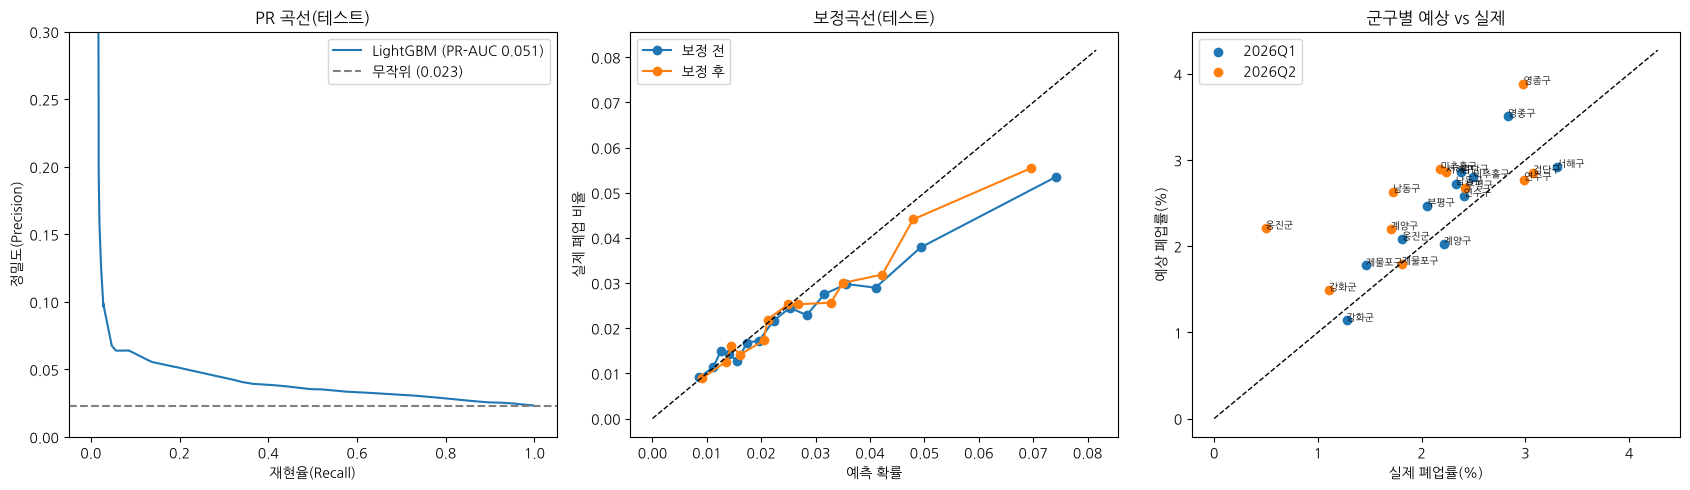

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
pr_, rc_, _ = precision_recall_curve(yte, p_te)
ax[0].plot(rc_, pr_, label=f"LightGBM (PR-AUC {average_precision_score(yte, p_te):.3f})")
ax[0].axhline(yte.mean(), ls="--", c="gray", label=f"무작위 ({yte.mean():.3f})")
ax[0].set(xlabel="재현율(Recall)", ylabel="정밀도(Precision)", title="PR 곡선(테스트)", ylim=(0, 0.3)); ax[0].legend()
lim = 0
for nm, pp in [("보정 전", p_te_raw), ("보정 후", p_te)]:
    fy, fx = calibration_curve(yte, pp, n_bins=15, strategy="quantile"); ax[1].plot(fx, fy, "o-", label=nm)
    lim = max(lim, fx.max(), fy.max())
ax[1].plot([0, lim * 1.1], [0, lim * 1.1], "k--", lw=1); ax[1].set(xlabel="예측 확률", ylabel="실제 폐업 비율", title="보정곡선(테스트)"); ax[1].legend()
for q, g in gu.groupby("기준분기"):
    ax[2].scatter(g["실제폐업률(%)"], g["예상폐업률(%)"], label=q)
    for _, r in g.iterrows(): ax[2].annotate(r["군구명_개편후"], (r["실제폐업률(%)"], r["예상폐업률(%)"]), fontsize=7)
m = gu[["실제폐업률(%)", "예상폐업률(%)"]].values.max() * 1.1
ax[2].plot([0, m], [0, m], "k--", lw=1); ax[2].set(xlabel="실제 폐업률(%)", ylabel="예상 폐업률(%)", title="군구별 예상 vs 실제"); ax[2].legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig1_PR곡선_보정곡선_군구비교.png", dpi=150); plt.show()

### 시계열 교차검증(안정성)
학습 기간을 한 분기씩 늘려 가며 다음 분기를 예측합니다(2024Q3~2025Q4, 6개 폴드).
폴드마다 성능이 얼마나 흔들리는지 봅니다. 트리 수는 위에서 정한 값으로 고정합니다.

In [14]:
folds = []
for e in range(7, 13):
    a, b = df[df[T] <= e - 1], df[df[T] == e]
    m = lgb.train(PARAMS, lgb.Dataset(a[FEATURES], a[Y]), num_boost_round=model.best_iteration)
    folds.append(evaluate(b[Y], m.predict(b[FEATURES]), b["기준분기"].iloc[0]))
folds = pd.DataFrame(folds).set_index("구분")[["관측치", "폐업비율", "PR-AUC", "PR-AUC/무작위", "ROC-AUC", "Recall@10%"]]
folds.loc["평균"] = folds.mean(); folds.loc["표준편차"] = folds.iloc[:-1].std()
folds.round(4).to_csv(f"{RESULT_DIR}/07_시계열교차검증.csv", encoding="utf-8-sig")
folds.round(4)

,관측치,폐업비율,PR-AUC,PR-AUC/무작위,ROC-AUC,Recall@10%
구분,,,,,,
2024Q3,38608.0000,0.0405,0.0850,2.1008,0.6491,0.2330
2024Q4,37974.0000,0.0258,0.0478,1.8535,0.6436,0.2082
2025Q1,37765.0000,0.0247,0.0487,1.9717,0.6472,0.2124
2025Q2,37659.0000,0.0224,0.0459,2.0435,0.6430,0.2083
2025Q3,37721.0000,0.0365,0.0752,2.0589,0.6562,0.2215
2025Q4,37171.0000,0.0248,0.0488,1.9658,0.6368,0.2028
평균,37816.3333,0.0291,0.0585,1.9990,0.6460,0.2144
표준편차,470.0058,0.0074,0.0170,0.0883,0.0066,0.0111


## 5. SHAP 변수 중요도
SHAP 값은 각 변수가 그 사업체의 폐업 예측을 얼마나 올리거나(+) 내렸는지(−)를 나타냅니다(로그오즈 단위).
변수 중요도는 테스트 데이터 전체에서 |SHAP|의 평균으로 계산합니다.

In [15]:
explainer = shap.TreeExplainer(model)
sv = explainer.shap_values(te[FEATURES]); sv = sv[1] if isinstance(sv, list) else sv
X_te = te[FEATURES].reset_index(drop=True)

imp = pd.DataFrame({"변수": FEATURES, "평균|SHAP|": np.abs(sv).mean(0),
                    "평균SHAP(+면 위험↑)": sv.mean(0),
                    "값과 SHAP의 상관(+면 값이 클수록 위험↑)": [np.corrcoef(X_te[c].fillna(X_te[c].median()), sv[:, i])[0, 1]
                                                   if X_te[c].nunique() > 1 else np.nan for i, c in enumerate(FEATURES)]})
imp = imp.sort_values("평균|SHAP|", ascending=False).reset_index(drop=True)
imp["순위"] = imp.index + 1
imp["비중(%)"] = imp["평균|SHAP|"] / imp["평균|SHAP|"].sum() * 100
imp = imp[["순위", "변수", "평균|SHAP|", "비중(%)", "값과 SHAP의 상관(+면 값이 클수록 위험↑)"]]
imp.round(4).to_csv(f"{RESULT_DIR}/08_SHAP_변수중요도.csv", encoding="utf-8-sig", index=False)
imp.round(4)

,순위,변수,평균|SHAP|,비중(%),값과 SHAP의 상관(+면 값이 클수록 위험↑)
0,1,업력개월,0.3736,34.0375,-0.8148
1,2,시설규모_log,0.1874,17.0762,-0.8337
2,3,읍면동_폐업률_4Q평균,0.0554,5.0437,0.7422
3,4,시간순번,0.0548,4.9902,0.0800
4,5,분기번호,0.0408,3.7180,0.0510
5,6,군구_총인구,0.0401,3.6554,0.5860
6,7,군구업태_폐업률_4Q평균,0.0354,3.2294,0.6209
7,8,군구_인구천명당_동일업태점포수,0.0304,2.7704,-0.7518
8,9,읍면동_폐업률_lag4,0.0289,2.6352,0.7907
9,10,군구_인구천명당_전체점포수,0.0243,2.2183,0.4617


In [16]:
# 변수군별로 묶은 중요도(비슷한 변수끼리 중요도가 나뉘는 문제를 보완)
GROUPS = {"업태": ["업태구분_2진수", "읍면동업태_점포비중"],
          "사업체 특성": ["업력개월", "시설규모_log", "다중이용업소여부"],
          "시간": ["분기번호", "시간순번"],
          "군구 인구·수요": ["군구_총인구", "군구_인구증감률_QoQ", "군구_인구증감률_YoY", "군구_인구천명당_전체점포수", "군구_인구천명당_동일업태점포수"],
          "군구×업태 상권": ["군구업태_개업률", "군구업태_폐업률", "군구업태_폐업률_lag1", "군구업태_폐업률_lag4", "군구업태_폐업률_4Q평균", "군구업태_공급수요격차"],
          "읍면동 상권": ["읍면동_영업점포수", "읍면동_개업률", "읍면동_폐업률", "읍면동_점포수증감률", "읍면동_폐업률_lag1", "읍면동_폐업률_lag4", "읍면동_폐업률_4Q평균", "읍면동업태_영업점포수"]}
assert sorted(sum(GROUPS.values(), [])) == sorted(FEATURES)
gimp = pd.Series({g: np.abs(sv[:, [FEATURES.index(c) for c in cs]].sum(1)).mean() for g, cs in GROUPS.items()}).sort_values(ascending=False)
gimp = pd.DataFrame({"평균|SHAP합|": gimp, "비중(%)": gimp / gimp.sum() * 100})
gimp.round(4).to_csv(f"{RESULT_DIR}/09_SHAP_변수군중요도.csv", encoding="utf-8-sig")
gimp.round(4)

,평균|SHAP합|,비중(%)
사업체 특성,0.4113,59.8884
읍면동 상권,0.1043,15.1865
군구 인구·수요,0.0678,9.8672
군구×업태 상권,0.0566,8.2414
시간,0.0247,3.5961
업태,0.0221,3.2203


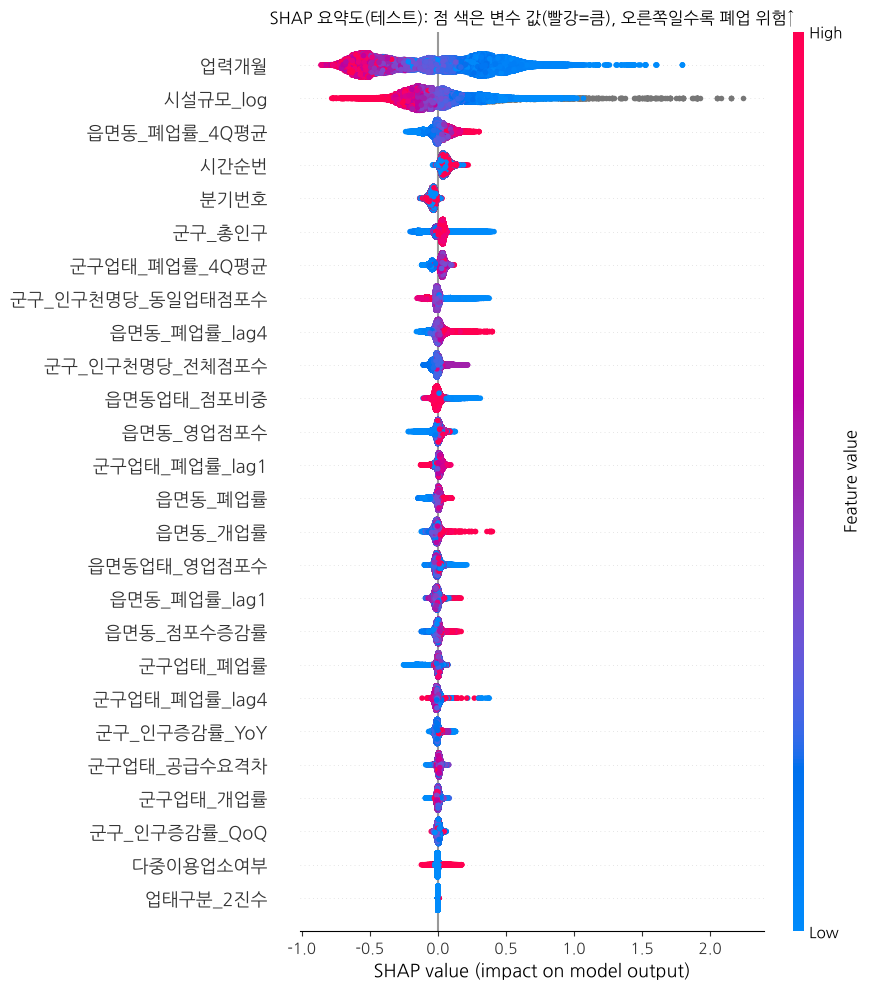

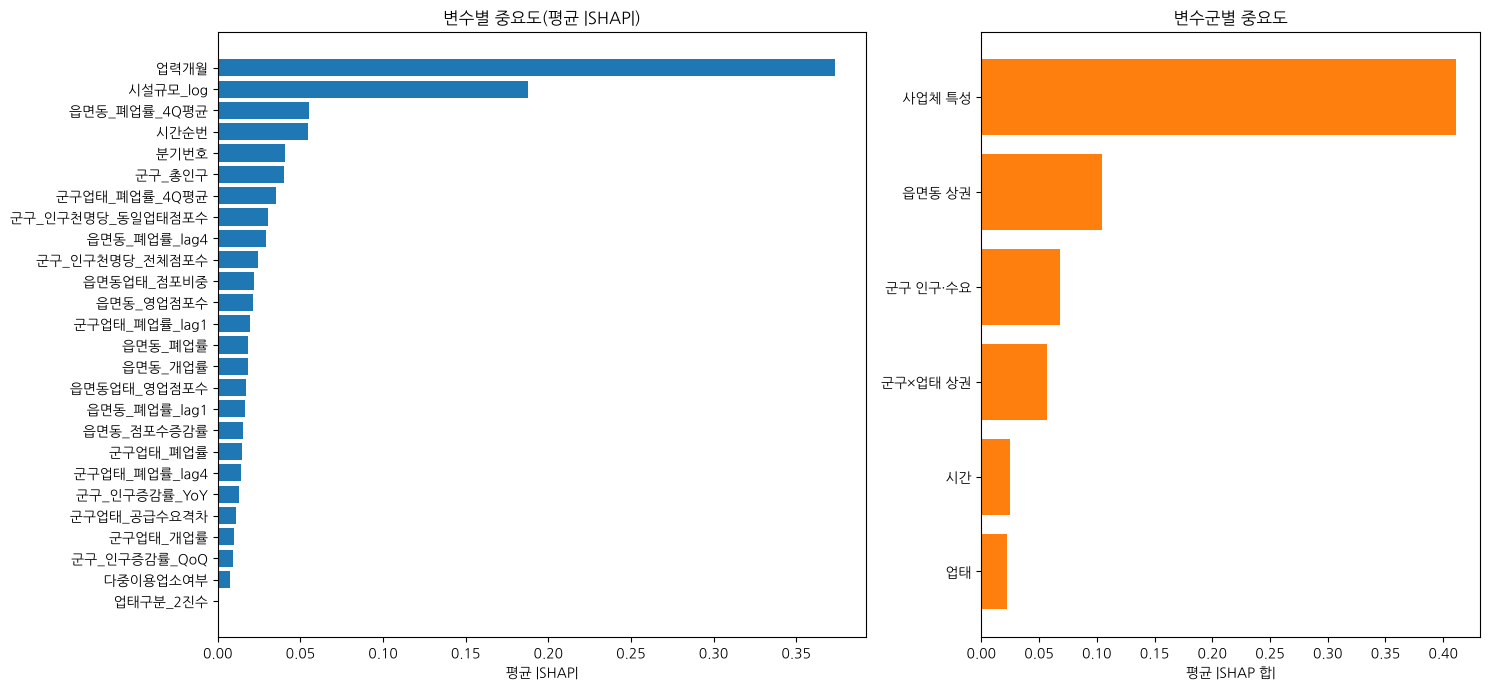

In [17]:
shap.summary_plot(sv, X_te, max_display=26, show=False, plot_size=(9, 10))
plt.title("SHAP 요약도(테스트): 점 색은 변수 값(빨강=큼), 오른쪽일수록 폐업 위험↑")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig2_SHAP_요약도.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [1.3, 1]})
ax[0].barh(imp["변수"][::-1], imp["평균|SHAP|"][::-1]); ax[0].set(title="변수별 중요도(평균 |SHAP|)", xlabel="평균 |SHAP|")
ax[1].barh(gimp.index[::-1], gimp["평균|SHAP합|"][::-1], color="tab:orange"); ax[1].set(title="변수군별 중요도", xlabel="평균 |SHAP 합|")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig3_SHAP_중요도_막대.png", dpi=150); plt.show()

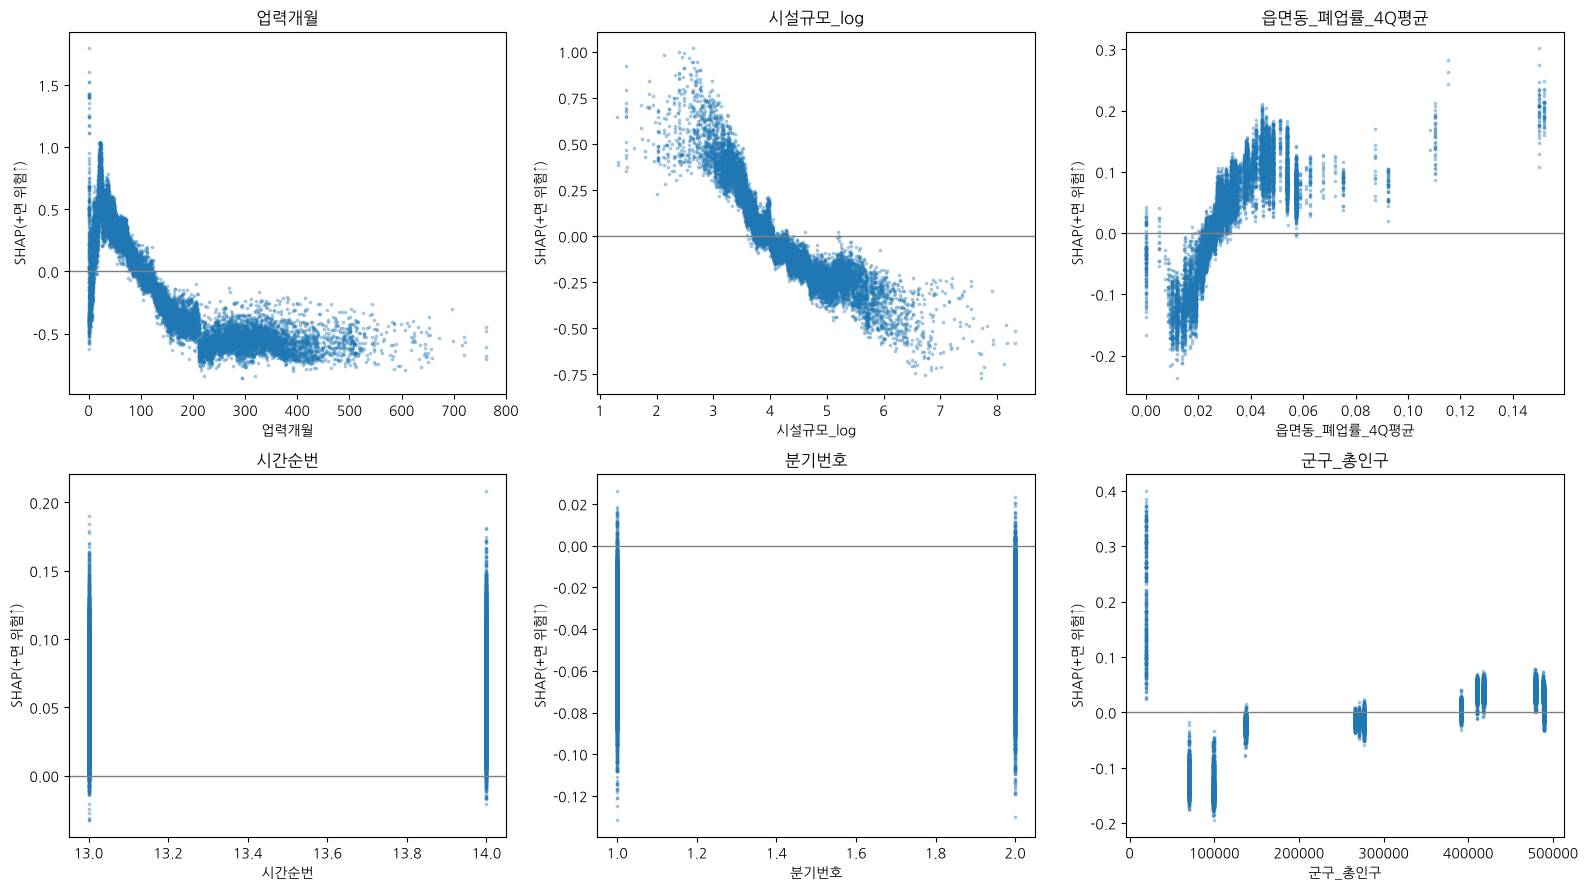

In [18]:
# 상위 6개 변수의 의존도: 변수 값에 따라 위험이 어떻게 변하는지
top6 = imp["변수"].head(6).tolist()
fig, axs = plt.subplots(2, 3, figsize=(16, 9))
rs = np.random.default_rng(SEED).choice(len(X_te), min(20000, len(X_te)), replace=False)
for a, c in zip(axs.ravel(), top6):
    a.scatter(X_te[c].values[rs], sv[rs, FEATURES.index(c)], s=3, alpha=.3); a.axhline(0, c="gray", lw=1)
    a.set(xlabel=c, ylabel="SHAP(+면 위험↑)", title=c)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig4_SHAP_의존도_상위6.png", dpi=150); plt.show()

## 6. 결과 파일
- `results/01_데이터분할.csv` ~ `09_SHAP_변수군중요도.csv`, `lgbm_model.txt`(학습된 모델)
- `figures/fig1` ~ `fig4`

In [19]:
print(sorted(os.listdir(RESULT_DIR))); print(sorted(os.listdir(FIG_DIR)))

['01_데이터분할.csv', '02_전체성능.csv', '03_부트스트랩_95CI.csv', '04_업태_군구별_성능.csv', '05_군구업태별_예상폐업률.csv', '06_집계정확도.csv', '07_시계열교차검증.csv', '08_SHAP_변수중요도.csv', '09_SHAP_변수군중요도.csv', 'lgbm_model.txt']
['fig1_PR곡선_보정곡선_군구비교.png', 'fig2_SHAP_요약도.png', 'fig3_SHAP_중요도_막대.png', 'fig4_SHAP_의존도_상위6.png']
